# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
in_ = '/hpc/group/hickeylab/fl135/pkl_data/'

i = 7
file_path = in_ + 'merfish_mouse_brain_slice' + str(i) + '.h5ad'
ad = sc.read(file_path)
ad.obs['original_clusters']=ad.obs['spa_cluster'].astype('category')
ad.obsm['spatial'] = ad.obsm['spatial'].to_numpy()[:, :2]
ad

AnnData object with n_obs × n_vars = 5749 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

In [3]:
file_path = in_ + 'merfish_mouse_brain_slice' + str(i-1) + '.h5ad'
ad_target = sc.read(file_path)
ad_target.obs['original_clusters']=ad_target.obs['spa_cluster'].astype('category')
ad_target.obsm['spatial'] = ad_target.obsm['spatial'].to_numpy()[:, :2]
ad_target

AnnData object with n_obs × n_vars = 4792 × 254
    obs: 'sample_id', 'slice_id', 'class_label', 'subclass', 'label', 'Astro_1', 'Endo', 'SMC', 'L23_IT_3', 'VLMC', 'L6_CT_5', 'L45_IT_2', 'L45_IT_SSp_2', 'Peri', 'L5_ET_1', 'L45_IT_1', 'L45_IT_5', 'L45_IT_3', 'L23_IT_4', 'L5_IT_1', 'Micro_1', 'L23_IT_2', 'L5_ET_5', 'Sst_3', 'L6_IT_3', 'Oligo_1', 'L5_ET_4', 'Sncg_1', 'L6_IT_Car3', 'Vip_7', 'PVM', 'L5_ET_3', 'L56_NP_1', 'Pvalb_6', 'L6_CT_3', 'L5_IT_2', 'L6_CT_1', 'L45_IT_SSp_1', 'Astro_2', 'Pvalb_5', 'L56_NP_2', 'Oligo_2', 'L6_IT_1', 'L6_CT_2', 'Pvalb_3', 'OPC', 'striatum_1', 'L5_IT_3', 'L23_IT_1', 'Oligo_3', 'Pvalb_4', 'Vip_1', 'L23_IT_5', 'L6_CT_6', 'Pvalb_1', 'Pvalb_7', 'L5_IT_4', 'L6b_2', 'L6_CT_4', 'Vip_3', 'Vip_10', 'striatum_2', 'Sst_2', 'L6_IT_2', 'L6b_1', 'L6_CT_8', 'Pvalb_10', 'L5_ET_2', 'L6_CT_7', 'Micro_2', 'L45_IT_4', 'Sst_1', 'Pvalb_2', 'Vip_6', 'Lamp5_1', 'L6b_3', 'ventricle_1', 'Lamp5_5', 'Sncg_2', 'Sst_6', 'Vip_8', 'Sst_5', 'Sst_4', 'Astro_3', 'Vip_2', 'Pvalb_8', 'Lamp5_9'

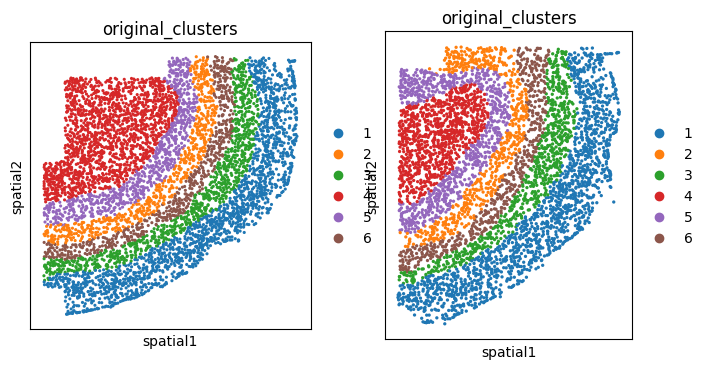

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], show=False)
plt.show()

0 of 4792
4791 of 4792


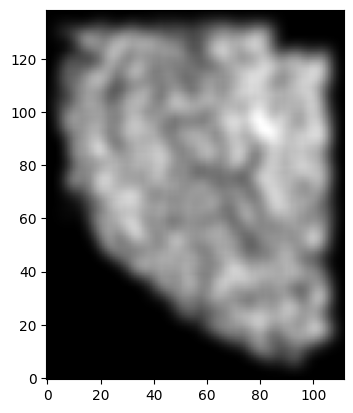

In [5]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = -spatial_coords_target[:, 0]
y_target = -spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=20,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 5749
5748 of 5749


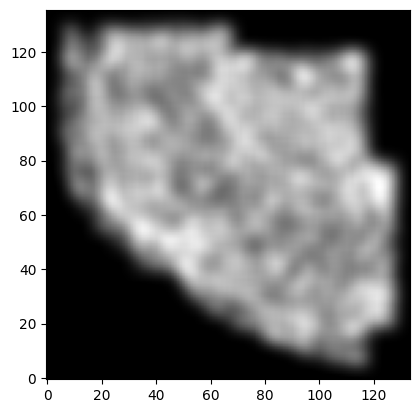

In [6]:
spatial_coords = ad.obsm['spatial']
x = -spatial_coords[:, 0]
y = -spatial_coords[:, 1]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=20,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

In [7]:
x_target = x_target - 1500
y_target = y_target - 3000

x = x + 5100
y = y - 2200

In [8]:
# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I = STalign.rasterize(x,y,dx=20,blur=1.5,draw=False)
XJ,YJ,J = STalign.rasterize(x_target,y_target,dx=20,blur=1.5,draw=False)

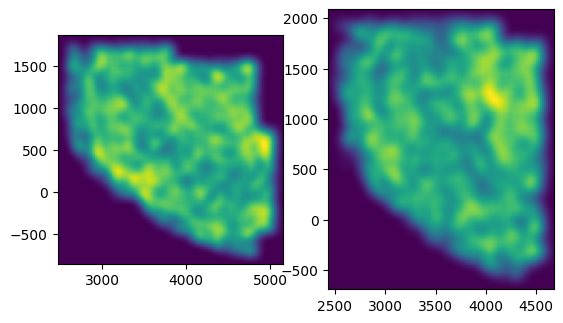

In [9]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 9min 34s, sys: 17.9 s, total: 9min 52s
Wall time: 10min 37s


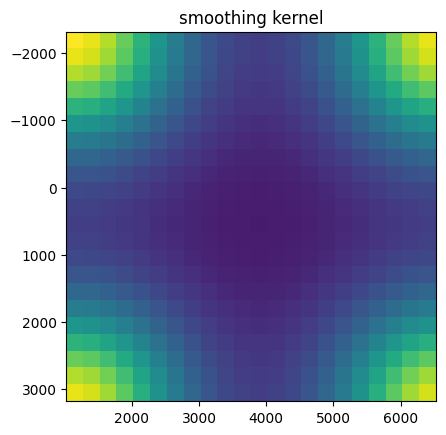

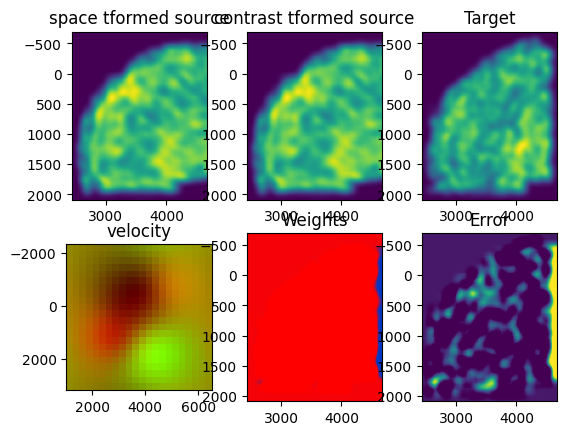

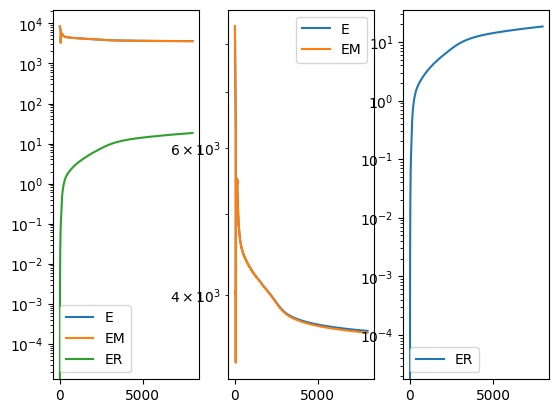

In [10]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':8000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.1, #standard deviation of artifact intensities
            'sigmaB': 0.1, #standard deviation of background intensities
            'sigmaM': 0.1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [26]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [27]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1).astype(np.float64))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

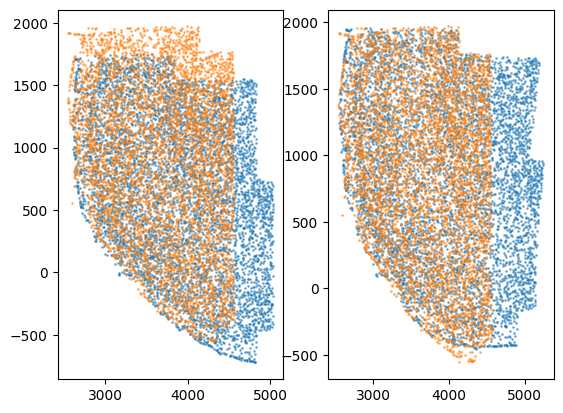

In [28]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [29]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [30]:
# Save as .pkl
alignment_df.to_pickle("6_7_AlignmentPi.pkl")

## LAA

In [32]:
def cal_layer_based_alignment_result_mHypothalamus(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    #l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    ir = 0
    max_smallerThan0 = []
    sum_smallerThan0 = []
    min_smallerThan0 = []

    for i, elem in enumerate(alignment):
        #if np.sum(elem)>0:
        if np.max(elem) - np.min(elem) != 0:
            if labels[i] == labels[elem.argmax() + alignment.shape[0]]:
                cnt0 += 1
        else:
            ir += 1
            max_smallerThan0.append(np.max(elem))
            sum_smallerThan0.append(np.sum(elem))
            min_smallerThan0.append(np.min(elem))
    print("the number of sum alignment equals 0:", str(cnt0))
    if len(sum_smallerThan0)>0:
        print("sum in sum alignment equals 0 is between", np.min(sum_smallerThan0), np.max(sum_smallerThan0))
        print("max in sum alignment equals 0 is between", np.min(max_smallerThan0), np.max(max_smallerThan0))
        print("min in sum alignment equals 0 is between", np.min(min_smallerThan0), np.max(min_smallerThan0))
    res.extend([cnt0])
    return res

In [33]:
res = cal_layer_based_alignment_result_mHypothalamus(alignment, ad, ad_target)
res[0]/len(ad.obs['original_clusters'])

the number of sum alignment equals 0: 987


0.1716820316576796

In [45]:
divisor = alignment.shape[0]
LAA_result = [num / divisor for num in res]
print(LAA_result)

[0.19082401278246974, 0.22095412006391235, 0.2565624286692536, 0.16388952293996806, 0.08970554667884045, 0.05957543939739785, 0.018488929468157955]


In [83]:
alignment.shape

(3611, 3596)

## ARI

In [34]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [35]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.594423134249441

## 3D

In [49]:
unique_clusters = ad.obs['original_clusters']
for jjj in range(1, 2):
    unique_clusters = sorted(np.unique(
        np.concatenate([
            unique_clusters,
            ad.obs['original_clusters']
        ])
    ))

In [50]:
cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))
c_dict

{'0': '#1f77b4',
 '1': '#ff7f0e',
 '2': '#2ca02c',
 '3': '#d62728',
 '4': '#9467bd',
 '5': '#8c564b',
 '6': '#e377c2'}

In [98]:
# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, np.stack([y, x], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

In [51]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,AAACAACGAATAGTTC-1,1
1,AAACAAGTATCTCCCA-1,3
2,AAACAATCTACTAGCA-1,1
3,AAACACCAATAACTGC-1,0
4,AAACAGCTTTCAGAAG-1,6


In [52]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 0
results1['slice'] = 151507
results1

,index,original_clusters,X,Y,Z,slice
0,AAACAACGAATAGTTC-1,1,3511.936336,2616.843970,0,151507
1,AAACAAGTATCTCCCA-1,3,9244.622874,8887.168666,0,151507
2,AAACAATCTACTAGCA-1,1,5230.460157,2961.065203,0,151507
3,AAACACCAATAACTGC-1,0,3447.657962,9986.173326,0,151507
4,AAACAGCTTTCAGAAG-1,6,2764.557799,7963.422832,0,151507
...,...,...,...,...,...,...
4216,TTGTTGTGTGTCAAGA-1,3,7502.154582,6493.307471,0,151507
4217,TTGTTTCACATCCAGG-1,6,5040.222115,9854.610336,0,151507
4218,TTGTTTCATTAGTCTA-1,0,4217.127602,10106.464999,0,151507
4219,TTGTTTCCATACAACT-1,6,4007.341016,8224.055294,0,151507


In [53]:
results1['celltype_colors'] = results1['original_clusters'].replace(c_dict)
results1

,index,original_clusters,X,Y,Z,slice,celltype_colors
0,AAACAACGAATAGTTC-1,1,3511.936336,2616.843970,0,151507,#ff7f0e
1,AAACAAGTATCTCCCA-1,3,9244.622874,8887.168666,0,151507,#d62728
2,AAACAATCTACTAGCA-1,1,5230.460157,2961.065203,0,151507,#ff7f0e
3,AAACACCAATAACTGC-1,0,3447.657962,9986.173326,0,151507,#1f77b4
4,AAACAGCTTTCAGAAG-1,6,2764.557799,7963.422832,0,151507,#e377c2
...,...,...,...,...,...,...,...
4216,TTGTTGTGTGTCAAGA-1,3,7502.154582,6493.307471,0,151507,#d62728
4217,TTGTTTCACATCCAGG-1,6,5040.222115,9854.610336,0,151507,#e377c2
4218,TTGTTTCATTAGTCTA-1,0,4217.127602,10106.464999,0,151507,#1f77b4
4219,TTGTTTCCATACAACT-1,6,4007.341016,8224.055294,0,151507,#e377c2


In [54]:
results1.to_csv("151507.csv", index=False)